In [7]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import sys
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path('/content/drive/MyDrive/pizza_rl_pj')
sys.path.insert(0, str(PROJECT_DIR))

from pizza_env_stage3 import PizzaKitchenStage3Env

print('Project directory:', PROJECT_DIR)
print('Environment file exists:', (PROJECT_DIR / 'pizza_env_stage3.py').exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/pizza_rl_pj
Environment file exists: True


In [8]:
import csv
from pathlib import Path
import numpy as np
import pandas as pd

from pizza_env_stage3 import PizzaKitchenStage3Env


# ---------------------------------------------------------
# 1. Greedy Action (Tie-breaking 보장)
# ---------------------------------------------------------
def greedy_action(q_values, rng):
    # Q-value 동률(Tie) 발생 시 무작위 선택하여 특정 행동 편향 방지
    return int(rng.choice(np.flatnonzero(q_values == q_values.max())))


# ---------------------------------------------------------
# 2. Stage 3 Q-Learning 학습 (FIFO 연동)
# ---------------------------------------------------------
def train_stage3(
    episodes=50_000,
    seed=42,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay=0.9999,
    log_every=10_000,
):
    """
    Stage 3 Q-Learning (FIFO 적용)
    - 주문 수: 4개
    - 메뉴 4종, 재료 5종 확장
    - Observation: Discrete (Sparse Q-table)
    - Action Space: 7가지 (0:Idle, 1~5:Ingredients, 6:Serve)
    """
    env = PizzaKitchenStage3Env(
        n_orders=4,
        min_deadline=6,
        max_deadline=16,
        observation_mode="discrete",
    )

    rng = np.random.default_rng(seed)
    q = {}
    history = []
    epsilon = epsilon_start

    print("--- Stage 3 (FIFO) Q-Learning 학습 시작 ---")
    print(f"상태 공간 크기: {env.observation_space.n:,}")
    print(f"행동 수: {env.action_space.n}")
    print(f"학습 에피소드: {episodes:,}")

    for episode in range(1, episodes + 1):
        state, _ = env.reset(seed=seed + episode)
        state = int(state)
        total_reward = 0.0
        done = False

        while not done:
            if state not in q:
                q[state] = np.zeros(env.action_space.n, dtype=np.float32)

            # Epsilon-Greedy 행동 선택 (Tie-breaking 적용)
            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = greedy_action(q[state], rng)

            next_state, reward, terminated, truncated, info = env.step(action)
            next_state = int(next_state)
            done = terminated or truncated

            if next_state not in q:
                q[next_state] = np.zeros(env.action_space.n, dtype=np.float32)

            # Q-learning Update (Bellman Equation)
            if done:
                target = reward
            else:
                target = reward + gamma * float(np.max(q[next_state]))

            q[state][action] += alpha * (target - q[state][action])

            state = next_state
            total_reward += reward

        epsilon = max(epsilon_end, epsilon * epsilon_decay)

        history.append({
            "episode": episode,
            "reward": total_reward,
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
            "epsilon": epsilon,
            "visited_states": len(q),
        })

        if episode % log_every == 0:
            recent = history[-log_every:]
            avg_reward = np.mean([x["reward"] for x in recent])
            avg_served = np.mean([x["served"] for x in recent])
            print(
                f"Episode {episode:5d}/{episodes} | "
                f"Avg Reward: {avg_reward:7.2f} | "
                f"Avg Served: {avg_served:.2f} | "
                f"Visited States: {len(q):,}"
            )

    env.close()
    print("\n--- Stage 3 학습 완료 ---")
    print(f"방문한 상태 수: {len(q):,}")

    return q, history


# ---------------------------------------------------------
# 3. Stage 3 모델 평가 (FIFO 연동)
# ---------------------------------------------------------
def evaluate_stage3(q, episodes=1_000, seed=10_000):
    env = PizzaKitchenStage3Env(
        n_orders=4,
        min_deadline=6,
        max_deadline=16,
        observation_mode="discrete",
    )

    rng = np.random.default_rng(seed)
    results = []

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        state = int(state)
        done = False
        total_reward = 0.0

        while not done:
            q_values = q.get(
                state,
                np.zeros(env.action_space.n, dtype=np.float32),
            )
            action = greedy_action(q_values, rng)

            state, reward, terminated, truncated, info = env.step(action)
            state = int(state)
            total_reward += reward
            done = terminated or truncated

        results.append({
            "episode": episode + 1,
            "return": total_reward,
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
        })

    env.close()

    total_orders = episodes * 4
    total_served = sum(x["served"] for x in results)

    performance = {
        "Total Evaluation Episodes": f"{episodes:,}",
        "Average Reward (Return)": f"{np.mean([x['return'] for x in results]):.2f}",
        "Order Completion Rate (%)": f"{(total_served / total_orders) * 100:.2f}%",
        "Average Served Orders (Max 4)": f"{np.mean([x['served'] for x in results]):.2f} / 4.0",
        "Average Expired Orders": f"{np.mean([x['expired'] for x in results]):.2f}",
        "Average Wrong Serves": f"{np.mean([x['wrong_serves'] for x in results]):.2f}",
        "Average Steps per Episode": f"{np.mean([x['steps'] for x in results]):.2f}",
    }

    return performance, results


# ---------------------------------------------------------
# 4. 결과 저장 함수
# ---------------------------------------------------------
def save_stage3_results(q, history, performance, evaluation_results):
    output_dir = Path("/content/drive/MyDrive/pizza_rl_pj/results_stage3")
    output_dir.mkdir(parents=True, exist_ok=True)

    # Sparse Q-table: states 및 values 추출 (Action 7개 기준)
    states = np.asarray(list(q.keys()), dtype=np.int64)
    values = (
        np.stack([q[state] for state in states]).astype(np.float32)
        if len(states) > 0
        else np.empty((0, 7), dtype=np.float32)
    )

    np.savez_compressed(
        output_dir / "q_table_stage3.npz",
        states=states,
        values=values,
    )

    history_path = output_dir / "q_learning_history_stage3.csv"
    with history_path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
        writer.writeheader()
        writer.writerows(history)

    evaluation_path = output_dir / "test_performance_stage3.csv"
    with evaluation_path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(evaluation_results[0].keys()))
        writer.writeheader()
        writer.writerows(evaluation_results)

    performance_path = output_dir / "performance_summary_stage3.csv"
    with performance_path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.writer(f)
        writer.writerow(["Metric", "Value"])
        writer.writerows(performance.items())

    print(f"\nSaved Stage 3 results to: {output_dir}")
    return output_dir


# ---------------------------------------------------------
# 5. 실행 메인 영역
# ---------------------------------------------------------
if __name__ == "__main__":
    # 1) 학습 진행
    q, history = train_stage3(
        episodes=50_000,
        seed=42,
        alpha=0.1,
        gamma=0.99,
        epsilon_start=1.0,
        epsilon_end=0.05,
        epsilon_decay=0.9999,
    )

    # 2) 평가 진행
    performance, evaluation_results = evaluate_stage3(
        q,
        episodes=1_000,
        seed=10_000,
    )

    # 3) 결과 요약 출력
    print("\n" + "=" * 55)
    print(" [Stage 3 (FIFO) Q-Learning Test Performance Summary]")
    print("=" * 55)
    for metric, value in performance.items():
        print(f"{metric}: {value}")
    print("=" * 55)

    # 4) 파일 저장
    save_stage3_results(q, history, performance, evaluation_results)

--- Stage 3 (FIFO) Q-Learning 학습 시작 ---
상태 공간 크기: 1,670,420,000
행동 수: 7
학습 에피소드: 50,000
Episode 10000/50000 | Avg Reward:  -62.80 | Avg Served: 0.18 | Visited States: 109,101
Episode 20000/50000 | Avg Reward:  -56.33 | Avg Served: 0.33 | Visited States: 209,195
Episode 30000/50000 | Avg Reward:  -51.10 | Avg Served: 0.46 | Visited States: 306,287
Episode 40000/50000 | Avg Reward:  -47.20 | Avg Served: 0.56 | Visited States: 401,646
Episode 50000/50000 | Avg Reward:  -45.82 | Avg Served: 0.60 | Visited States: 495,131

--- Stage 3 학습 완료 ---
방문한 상태 수: 495,131

 [Stage 3 (FIFO) Q-Learning Test Performance Summary]
Total Evaluation Episodes: 1,000
Average Reward (Return): -42.00
Order Completion Rate (%): 17.35%
Average Served Orders (Max 4): 0.69 / 4.0
Average Expired Orders: 3.31
Average Wrong Serves: 0.45
Average Steps per Episode: 13.94

Saved Stage 3 results to: /content/drive/MyDrive/pizza_rl_pj/results_stage3


 Stage 3 시각화 대시보드가 성공적으로 저장되었습니다:
- /content/drive/MyDrive/pizza_rl_pj/results_stage3/performance_dashboard_stage3.png


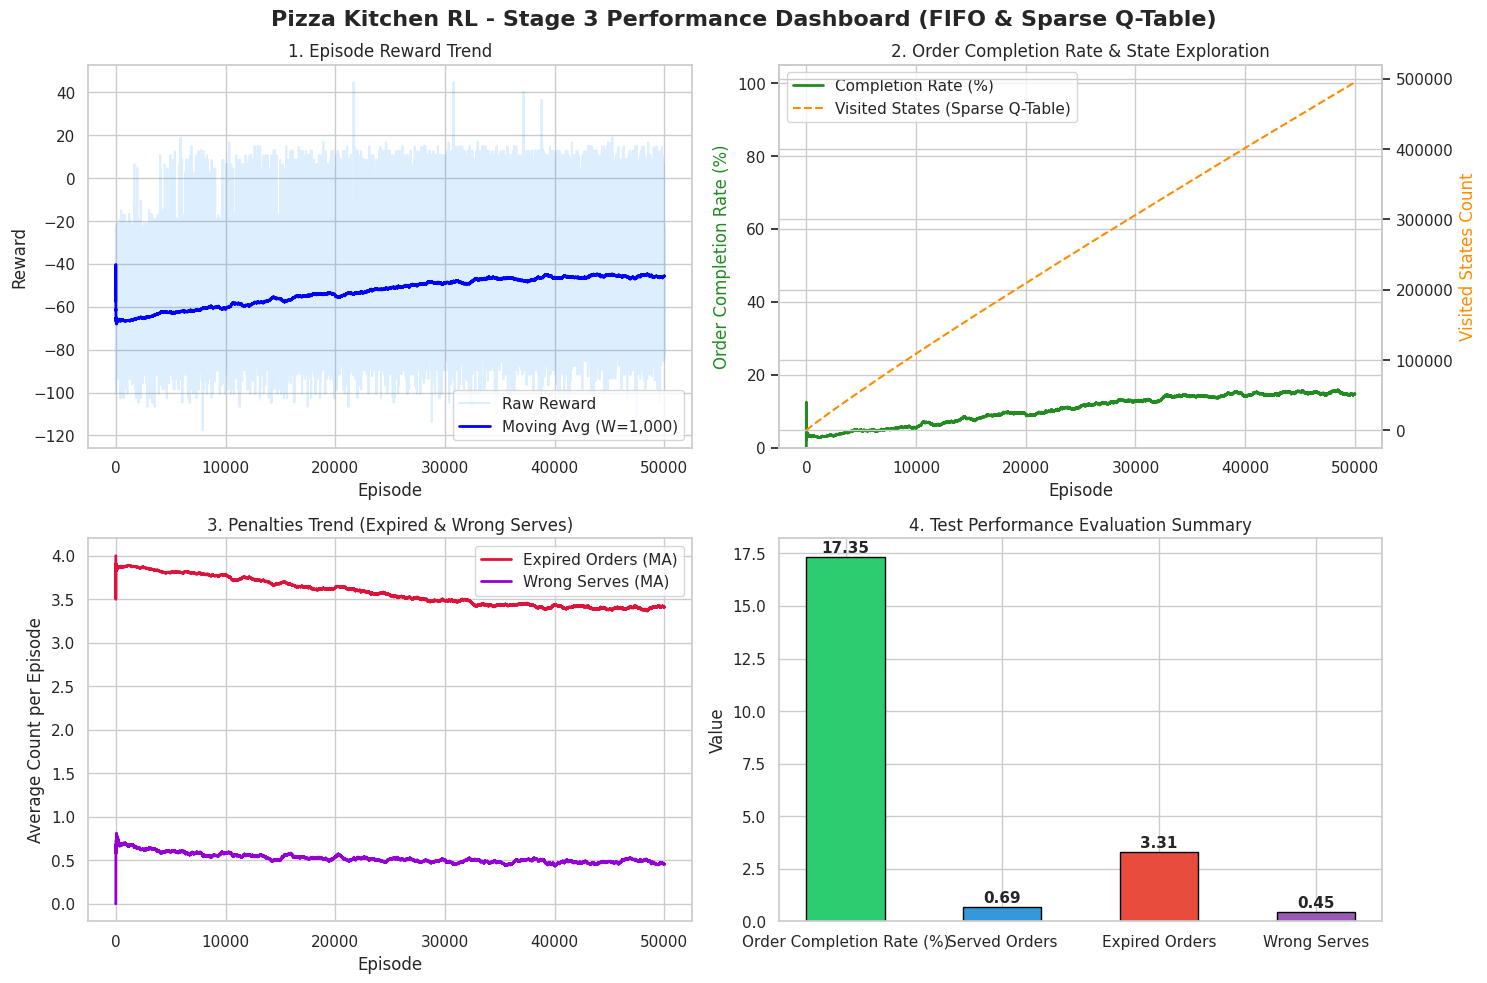

In [9]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. 스타일 및 한글/글꼴 설정
sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 11

# 2. 결과 파일 경로 설정 (Stage 3 경로)
output_dir = Path("/content/drive/MyDrive/pizza_rl_pj/results_stage3")
history_path = output_dir / "q_learning_history_stage3.csv"
performance_path = output_dir / "performance_summary_stage3.csv"

# 3. 파일 존재 여부 확인 및 데이터 로드
if not history_path.exists():
    raise FileNotFoundError(f"학습 기록 파일이 존재하지 않습니다: {history_path}")

history_df = pd.read_csv(history_path)

# 4. 데이터 전처리 (이동 평균 계산)
WINDOW = 1000  # 이동 평균 구간 (에피소드 수)
n_orders = 4   # Stage 3 주문 수 (4개)

# 이동 평균 열 생성
history_df["reward_ma"] = history_df["reward"].rolling(window=WINDOW, min_periods=1).mean()
history_df["served_ma"] = history_df["served"].rolling(window=WINDOW, min_periods=1).mean()
history_df["completion_rate_ma"] = (history_df["served_ma"] / n_orders) * 100

history_df["expired_ma"] = history_df["expired"].rolling(window=WINDOW, min_periods=1).mean()
history_df["wrong_serves_ma"] = history_df["wrong_serves"].rolling(window=WINDOW, min_periods=1).mean()

# 5. 2x2 시각화 대시보드 생성
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(
    "Pizza Kitchen RL - Stage 3 Performance Dashboard (FIFO & Sparse Q-Table)",
    fontsize=16,
    fontweight="bold",
)

# [Graph 1] Episode Reward Trend
axes[0, 0].plot(
    history_df["episode"],
    history_df["reward"],
    alpha=0.15,
    color="dodgerblue",
    label="Raw Reward",
)
axes[0, 0].plot(
    history_df["episode"],
    history_df["reward_ma"],
    color="blue",
    linewidth=2,
    label=f"Moving Avg (W={WINDOW:,})",
)
axes[0, 0].set_title("1. Episode Reward Trend")
axes[0, 0].set_xlabel("Episode")
axes[0, 0].set_ylabel("Reward")
axes[0, 0].legend(loc="lower right")

# [Graph 2] Completion Rate (%) & Visited States Count (Dual Y-Axis)
ax2_twin = axes[0, 1].twinx()
p1 = axes[0, 1].plot(
    history_df["episode"],
    history_df["completion_rate_ma"],
    color="forestgreen",
    linewidth=2,
    label="Completion Rate (%)",
)
p2 = ax2_twin.plot(
    history_df["episode"],
    history_df["visited_states"],
    color="darkorange",
    linewidth=1.5,
    linestyle="--",
    label="Visited States (Sparse Q-Table)",
)

axes[0, 1].set_title("2. Order Completion Rate & State Exploration")
axes[0, 1].set_xlabel("Episode")
axes[0, 1].set_ylabel("Order Completion Rate (%)", color="forestgreen")
ax2_twin.set_ylabel("Visited States Count", color="darkorange")
axes[0, 1].set_ylim(0, 105)

# 범례 통합
lines = p1 + p2
labels = [l.get_label() for l in lines]
axes[0, 1].legend(lines, labels, loc="upper left")

# [Graph 3] Penalties Trend (Expired & Wrong Serves)
axes[1, 0].plot(
    history_df["episode"],
    history_df["expired_ma"],
    color="crimson",
    linewidth=2,
    label="Expired Orders (MA)",
)
axes[1, 0].plot(
    history_df["episode"],
    history_df["wrong_serves_ma"],
    color="darkviolet",
    linewidth=2,
    label="Wrong Serves (MA)",
)
axes[1, 0].set_title("3. Penalties Trend (Expired & Wrong Serves)")
axes[1, 0].set_xlabel("Episode")
axes[1, 0].set_ylabel("Average Count per Episode")
axes[1, 0].legend(loc="upper right")

# [Graph 4] Final Evaluation Summary (Performance Metrics Bar Chart)
if performance_path.exists():
    df_perf = pd.read_csv(performance_path, header=None, names=["Metric", "Value"])

    # 딕셔너리로 변환하여 원하는 지표만 추출
    perf_dict = {}
    for _, row in df_perf.iterrows():
        try:
            # 수치형 변환 시도 (문자열 포맷 제거)
            val_str = str(row["Value"]).replace("%", "").split("/")[0].strip()
            perf_dict[row["Metric"]] = float(val_str)
        except ValueError:
            continue

    metrics_to_plot = [
        "Order Completion Rate (%)",
        "Average Served Orders (Max 4)",
        "Average Expired Orders",
        "Average Wrong Serves",
    ]

    # 존재하는 지표만 필터링
    plot_labels = []
    plot_values = []
    for m in metrics_to_plot:
        if m in perf_dict:
            plot_labels.append(m.replace("Average ", "").replace(" (Max 4)", ""))
            plot_values.append(perf_dict[m])

    colors = ["#2ecc71", "#3498db", "#e74c3c", "#9b59b6"]
    bars = axes[1, 1].bar(
        plot_labels, plot_values, color=colors[:len(plot_values)], width=0.5, edgecolor="black"
    )
    axes[1, 1].set_title("4. Test Performance Evaluation Summary")
    axes[1, 1].set_ylabel("Value")

    # 막대 그래프 위 값 명시
    for bar in bars:
        yval = bar.get_height()
        axes[1, 1].text(
            bar.get_x() + bar.get_width() / 2,
            yval + (0.05 if yval >= 0 else -0.1),
            f"{yval:.2f}",
            ha="center",
            va="bottom",
            fontweight="bold",
        )
else:
    axes[1, 1].text(
        0.5, 0.5, "Performance Summary File Not Found", ha="center", va="center", fontsize=12
    )
    axes[1, 1].set_title("4. Test Performance Summary")

plt.tight_layout()

# 6. 이미지 저장 및 출력
save_fig_path = output_dir / "performance_dashboard_stage3.png"
plt.savefig(save_fig_path, dpi=300)
print(f" Stage 3 시각화 대시보드가 성공적으로 저장되었습니다:\n- {save_fig_path}")

plt.show()